# Challenge 1: datos y análisis exploratorio

Tu primera responsabilidad es preparar una fuente de datos confiable para el proyecto de clasificación de vinos.

**Entrada:** `data/raw/wine.csv`  
**Salidas:** `data/processed/train.csv`, `data/processed/test.csv` y `artifacts/data_contract.json`

> El conjunto de test se crea aquí, pero no debe explorarse ni utilizarse después del split.

## Objetivos

- cargar y validar datos externos;
- identificar problemas básicos de calidad;
- crear un split reproducible y estratificado;
- realizar EDA únicamente sobre entrenamiento;
- guardar datos y metadatos para la siguiente etapa.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

np.random.seed(42)
plt.rcParams["figure.figsize"] = (7, 4)

In [2]:
from pathlib import Path

PROJECT_DIR = Path.cwd()
RAW_DATA_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DATA_DIR = PROJECT_DIR / "data" / "processed"
ARTIFACTS_DIR = PROJECT_DIR / "artifacts"
REPORTS_DIR = PROJECT_DIR / "reports"

for directory in (PROCESSED_DATA_DIR, ARTIFACTS_DIR, REPORTS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42

## 1. Carga y profiling

In [3]:
DATA_PATH = RAW_DATA_DIR / "wine.csv"
df = pd.read_csv(DATA_PATH)
df.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


In [4]:
print("Forma:", df.shape)
print()
print(df.dtypes.value_counts())
print()
print("Nulos totales:", int(df.isna().sum().sum()))
print("Filas duplicadas:", int(df.duplicated().sum()))
print()
print("Distribución de target:")
print(df["target"].value_counts().sort_index())
print()
df.describe().T

Forma: (178, 14)

float64    13
int64       1
Name: count, dtype: int64

Nulos totales: 0
Filas duplicadas: 0

Distribución de target:
target
0    59
1    71
2    48
Name: count, dtype: int64



,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,13.000618,0.811827,11.03,12.3625,13.050,13.6775,14.83
malic_acid,178.0,2.336348,1.117146,0.74,1.6025,1.865,3.0825,5.80
ash,178.0,2.366517,0.274344,1.36,2.2100,2.360,2.5575,3.23
alcalinity_of_ash,178.0,19.494944,3.339564,10.60,17.2000,19.500,21.5000,30.00
magnesium,178.0,99.741573,14.282484,70.00,88.0000,98.000,107.0000,162.00
total_phenols,178.0,2.295112,0.625851,0.98,1.7425,2.355,2.8000,3.88
flavanoids,178.0,2.029270,0.998859,0.34,1.2050,2.135,2.8750,5.08
nonflavanoid_phenols,178.0,0.361854,0.124453,0.13,0.2700,0.340,0.4375,0.66
proanthocyanins,178.0,1.590899,0.572359,0.41,1.2500,1.555,1.9500,3.58
color_intensity,178.0,5.058090,2.318286,1.28,3.2200,4.690,6.2000,13.00


**Conclusión de calidad:**

El archivo tiene 178 filas y 14 columnas, todas numéricas. No se encontraron valores nulos ni filas duplicadas, por lo que no fue necesario eliminar registros. Las clases 0, 1 y 2 tienen 59, 71 y 48 ejemplos, un desbalance moderado que justifica usar un split estratificado. Las variables están en escalas muy distintas, por ejemplo proline llega a valores cercanos a 1700 mientras hue está alrededor de 1, lo que se tiene en cuenta para los modelos sensibles a la escala.

## 2. Split train/test

In [5]:
train_df, test_df = train_test_split(
    df,
    test_size=0.20,
    stratify=df["target"],
    random_state=RANDOM_STATE,
)

In [6]:
# Verificación del split
assert len(train_df) + len(test_df) == len(df)
assert set(train_df.index).isdisjoint(set(test_df.index))
print("Train:", train_df.shape)
print("Test:", test_df.shape)

Train: (142, 14)
Test: (36, 14)


## 3. EDA sobre entrenamiento

Incluye:

- distribución de clases;
- distribuciones o boxplots de variables relevantes;
- correlaciones;
- tres hallazgos que puedan influir en el modelado.

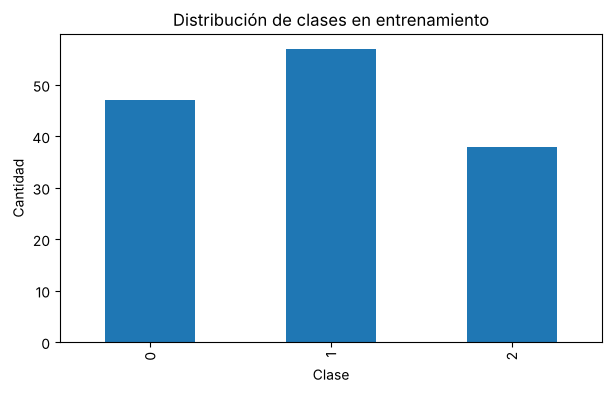

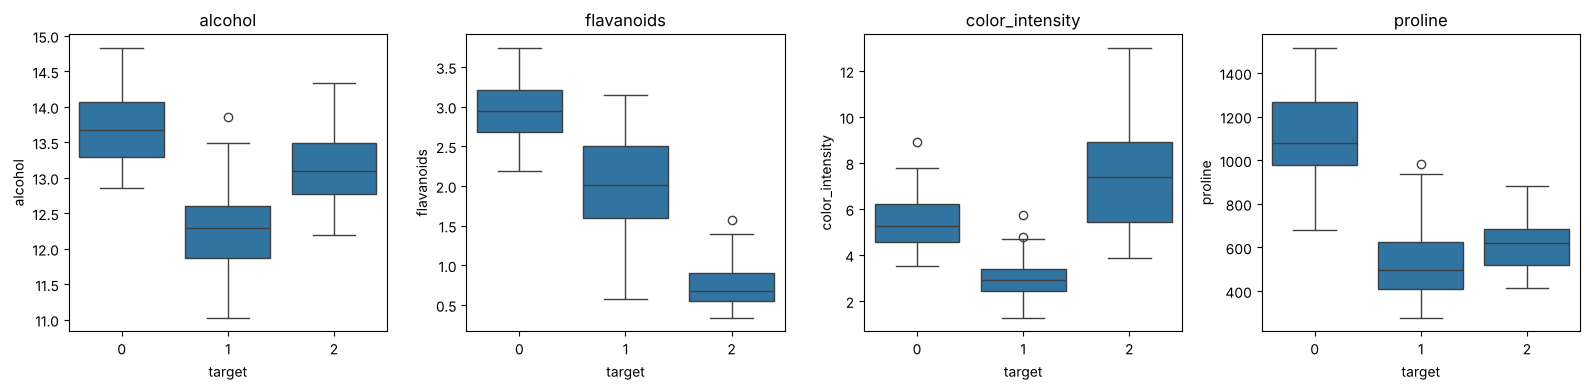

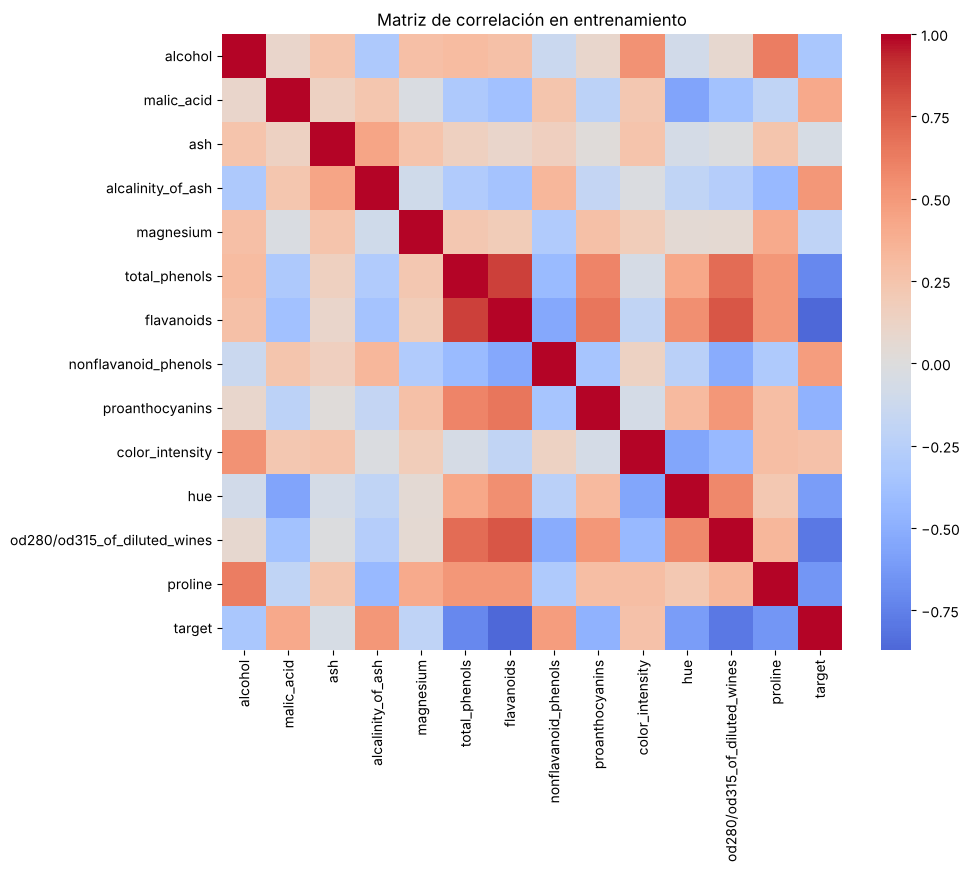

flavanoids                     -0.870180
od280/od315_of_diluted_wines   -0.784280
total_phenols                  -0.713752
proline                        -0.638823
hue                            -0.605732
proanthocyanins                -0.481488
alcohol                        -0.331843
magnesium                      -0.207569
ash                            -0.044951
color_intensity                 0.268592
malic_acid                      0.418279
nonflavanoid_phenols            0.476767
alcalinity_of_ash               0.507562
Name: target, dtype: float64

                                 min      max         std
alcohol                        11.03    14.83    0.802521
malic_acid                      0.74     5.80    1.101285
ash                             1.36     3.22    0.268380
alcalinity_of_ash              10.60    30.00    3.380848
magnesium                      70.00   162.00   14.937448
total_phenols                   0.98     3.88    0.621454
flavanoids                     

In [7]:
# Distribución de clases
train_df["target"].value_counts().sort_index().plot(kind="bar")
plt.title("Distribución de clases en entrenamiento")
plt.xlabel("Clase")
plt.ylabel("Cantidad")
plt.show()

# Boxplots de variables relevantes por clase
features_box = ["alcohol", "flavanoids", "color_intensity", "proline"]
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, features_box):
    sns.boxplot(data=train_df, x="target", y=col, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

# Correlaciones
plt.figure(figsize=(10, 8))
sns.heatmap(train_df.corr(), cmap="coolwarm", center=0, annot=False)
plt.title("Matriz de correlación en entrenamiento")
plt.show()

print(train_df.corr()["target"].drop("target").sort_values())
print()
print(train_df.drop(columns="target").describe().loc[["min", "max", "std"]].T)

**Hallazgos:**

Primero, flavanoids, od280/od315 y total_phenols tienen las correlaciones más fuertes con la clase, y en los boxplots separan con claridad la clase 2 de la clase 0. Segundo, alcohol y proline distinguen sobre todo la clase 1, que presenta valores bajos en ambas, lo que sugiere que pocas variables bastan para separar las tres clases. Tercero, existe alta correlación entre flavanoids y total_phenols y diferencias grandes de escala entre variables, por lo que conviene escalar los datos y preferir modelos regularizados o basados en distancias normalizadas.

## 4. Persistencia de datos y contrato

In [8]:
train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

train_df.to_csv(PROCESSED_DATA_DIR / "train.csv", index=False)
test_df.to_csv(PROCESSED_DATA_DIR / "test.csv", index=False)

features = [c for c in df.columns if c != "target"]
contract = {
    "target": "target",
    "features": features,
    "random_state": RANDOM_STATE,
    "test_size": 0.20,
    "classes": sorted(int(c) for c in df["target"].unique()),
    "n_train": len(train_df),
    "n_test": len(test_df),
}
(ARTIFACTS_DIR / "data_contract.json").write_text(json.dumps(contract, indent=2), encoding="utf-8")
contract

{'target': 'target',
 'features': ['alcohol',
  'malic_acid',
  'ash',
  'alcalinity_of_ash',
  'magnesium',
  'total_phenols',
  'flavanoids',
  'nonflavanoid_phenols',
  'proanthocyanins',
  'color_intensity',
  'hue',
  'od280/od315_of_diluted_wines',
  'proline'],
 'random_state': 42,
 'test_size': 0.2,
 'classes': [0, 1, 2],
 'n_train': 142,
 'n_test': 36}

In [9]:
# Verificación de entrega
assert (PROCESSED_DATA_DIR / "train.csv").exists()
assert (PROCESSED_DATA_DIR / "test.csv").exists()
assert (ARTIFACTS_DIR / "data_contract.json").exists()
print("Challenge 1 completado.")

Challenge 1 completado.


## Checklist

- [x] Cargué el CSV desde `data/raw`.
- [x] Revisé calidad y distribución de la clase.
- [x] Realicé un split estratificado.
- [x] No exploré el conjunto de test.
- [x] Guardé los tres artefactos requeridos.